In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Python path:", sys.executable)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

print("SUCCESS - Matplotlib is working!")

Matplotlib is building the font cache; this may take a moment.


Python: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
Python path: C:\Users\dilee\anaconda3\envs\medical_chatbot\python.exe
Pandas: 3.1.1
Matplotlib: 3.11.2
SUCCESS - Matplotlib is working!


# Medical Q&A Chatbot

## Project Objective
To develop a medical question-answering chatbot using
Retrieval-Augmented Generation (RAG).

## Technologies
- Python
- Jupyter Notebook
- MedQuAD Dataset
- LangChain
- Hugging Face
- ChromaDB
- Groq LLM

## Project Workflow
1. Dataset collection
2. Data preprocessing
3. Exploratory Data Analysis
4. Text chunking
5. Embedding generation
6. Vector database creation
7. Information retrieval
8. LLM integration
9. Medical chatbot development
10. Testing and evaluation

**Disclaimer:** This chatbot is for educational purposes only.
It does not replace professional medical advice or diagnosis.

In [2]:
import os
import sys
import re
import zipfile
import requests
import xml.etree.ElementTree as ET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_groq import ChatGroq

print("All required libraries imported successfully!")

C:\Users\dilee\anaconda3\envs\medical_chatbot\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All required libraries imported successfully!


## Step 1: Create Project Folder Structure

In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
DATASET_DIR = DATA_DIR / "MedQuAD"

VECTOR_DIR = PROJECT_DIR / "vectorstore" / "chroma_db"
OUTPUT_DIR = PROJECT_DIR / "outputs"

for folder in [DATA_DIR, DATASET_DIR, VECTOR_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")
print("Project location:", PROJECT_DIR)

Project folders created successfully!
Project location: C:\Users\dilee


## Step 2: Download Medical Dataset

We are using the MedQuAD dataset.
It contains medical questions and answers collected
from trusted health information sources.

In [4]:
DATASET_URL = "https://github.com/abachaa/MedQuAD/archive/refs/heads/master.zip"

ZIP_PATH = DATA_DIR / "MedQuAD.zip"

print("Dataset download location:", ZIP_PATH)

Dataset download location: C:\Users\dilee\data\MedQuAD.zip


In [5]:
xml_files = list(DATASET_DIR.rglob("*.xml"))

if len(xml_files) == 0:

    print("Downloading MedQuAD dataset...")

    response = requests.get(DATASET_URL, timeout=180)
    response.raise_for_status()

    ZIP_PATH.write_bytes(response.content)

    print("Download completed!")

    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATASET_DIR)

    print("Extraction completed!")

else:
    print("Dataset already exists.")

xml_files = list(DATASET_DIR.rglob("*.xml"))

print("Total XML files:", len(xml_files))

assert len(xml_files) > 0, "No XML files found. Check the dataset download."

print("Dataset is ready!")

Dataset already exists.
Total XML files: 11274
Dataset is ready!


In [6]:
print("Project verification")
print("--------------------")

print("Python:", sys.version)
print("Dataset XML files:", len(xml_files))

print("Data folder:", DATA_DIR.exists())
print("Dataset folder:", DATASET_DIR.exists())
print("Vector folder:", VECTOR_DIR.exists())
print("Output folder:", OUTPUT_DIR.exists())

Project verification
--------------------
Python: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
Dataset XML files: 11274
Data folder: True
Dataset folder: True
Vector folder: True
Output folder: True


## Step 3: Extract Medical Questions and Answers

Read the XML files and extract:
- Medical topic
- Patient question
- Medical answer
- Source information

In [7]:
def get_tag_text(element, tag_name):
    for child in element.iter():
        tag = child.tag.split("}")[-1]

        if tag.lower() == tag_name.lower():
            return " ".join(child.itertext()).strip()

    return ""


def clean_text(text):
    if not text:
        return ""

    text = re.sub(r"\s+", " ", text)
    text = text.strip()

    return text

In [8]:
medical_records = []

for file_path in tqdm(xml_files, desc="Reading XML files"):

    try:
        tree = ET.parse(file_path)
        root = tree.getroot()

        topic = clean_text(get_tag_text(root, "Focus"))

        for element in root.iter():

            if element.tag.split("}")[-1].lower() != "qapair":
                continue

            question = clean_text(get_tag_text(element, "Question"))
            answer = clean_text(get_tag_text(element, "Answer"))

            if question and answer:

                medical_records.append({
                    "topic": topic if topic else "General",
                    "question": question,
                    "answer": answer,
                    "source_file": file_path.name
                })

    except Exception as error:
        print("Skipped:", file_path.name, "|", error)

print("Total extracted records:", len(medical_records))

Reading XML files: 100%|██████████| 11274/11274 [06:20<00:00, 29.63it/s]

Total extracted records: 16407


In [9]:
medical_df = pd.DataFrame(medical_records)

print("Dataset shape:", medical_df.shape)

medical_df.head()

Dataset shape: (16407, 4)


,topic,question,answer,source_file
0,Adult Acute Lymphoblastic Leukemia,What is (are) Adult Acute Lymphoblastic Leukem...,Key Points - Adult acute lymphoblastic leukemi...,0000001_1.xml
1,Adult Acute Lymphoblastic Leukemia,What are the symptoms of Adult Acute Lymphobla...,"Signs and symptoms of adult ALL include fever,...",0000001_1.xml
2,Adult Acute Lymphoblastic Leukemia,How to diagnose Adult Acute Lymphoblastic Leuk...,Tests that examine the blood and bone marrow a...,0000001_1.xml
3,Adult Acute Lymphoblastic Leukemia,What is the outlook for Adult Acute Lymphoblas...,Certain factors affect prognosis (chance of re...,0000001_1.xml
4,Adult Acute Lymphoblastic Leukemia,Who is at risk for Adult Acute Lymphoblastic L...,Previous chemotherapy and exposure to radiatio...,0000001_1.xml


In [10]:
print("Missing values:")
print(medical_df.isnull().sum())

print("\nDuplicate rows:")
print(medical_df.duplicated().sum())

print("\nDataset information:")
medical_df.info()

Missing values:
topic          0
question       0
answer         0
source_file    0
dtype: int64

Duplicate rows:
30

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 16407 entries, 0 to 16406
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   topic        16407 non-null  str  
 1   question     16407 non-null  str  
 2   answer       16407 non-null  str  
 3   source_file  16407 non-null  str  
dtypes: str(4)
memory usage: 512.8 KB


In [11]:
medical_df = medical_df.dropna(
    subset=["question", "answer"]
)

medical_df["question"] = medical_df["question"].apply(clean_text)
medical_df["answer"] = medical_df["answer"].apply(clean_text)
medical_df["topic"] = medical_df["topic"].apply(clean_text)

medical_df = medical_df[
    (medical_df["question"] != "") &
    (medical_df["answer"] != "")
]

medical_df = medical_df.drop_duplicates(
    subset=["question", "answer"]
)

medical_df = medical_df.reset_index(drop=True)

print("Cleaned dataset shape:", medical_df.shape)

medical_df.head()

Cleaned dataset shape: (16359, 4)


,topic,question,answer,source_file
0,Adult Acute Lymphoblastic Leukemia,What is (are) Adult Acute Lymphoblastic Leukem...,Key Points - Adult acute lymphoblastic leukemi...,0000001_1.xml
1,Adult Acute Lymphoblastic Leukemia,What are the symptoms of Adult Acute Lymphobla...,"Signs and symptoms of adult ALL include fever,...",0000001_1.xml
2,Adult Acute Lymphoblastic Leukemia,How to diagnose Adult Acute Lymphoblastic Leuk...,Tests that examine the blood and bone marrow a...,0000001_1.xml
3,Adult Acute Lymphoblastic Leukemia,What is the outlook for Adult Acute Lymphoblas...,Certain factors affect prognosis (chance of re...,0000001_1.xml
4,Adult Acute Lymphoblastic Leukemia,Who is at risk for Adult Acute Lymphoblastic L...,Previous chemotherapy and exposure to radiatio...,0000001_1.xml


## Step 4: Exploratory Data Analysis

Analyze the medical dataset to understand:
- Total medical questions
- Medical topics
- Question lengths
- Answer lengths

In [12]:
print("TOTAL MEDICAL RECORDS:", len(medical_df))

print("\nUNIQUE TOPICS:")
print(medical_df["topic"].nunique())

print("\nTOP 10 MEDICAL TOPICS:")
print(medical_df["topic"].value_counts().head(10))

TOTAL MEDICAL RECORDS: 16359

UNIQUE TOPICS:
5126

TOP 10 MEDICAL TOPICS:
topic
Breast Cancer             53
Prostate Cancer           43
Stroke                    35
Skin Cancer               34
Alzheimer's Disease       30
Lung Cancer               29
Colorectal Cancer         29
Heart Attack              28
Heart Failure             28
High Blood Cholesterol    28
Name: count, dtype: int64


In [13]:
medical_df["question_length"] = medical_df["question"].apply(
    lambda x: len(x.split())
)

medical_df["answer_length"] = medical_df["answer"].apply(
    lambda x: len(x.split())
)

print("Average question length:",
      medical_df["question_length"].mean())

print("Average answer length:",
      medical_df["answer_length"].mean())

Average question length: 8.214560792224464
Average answer length: 200.36658719970657


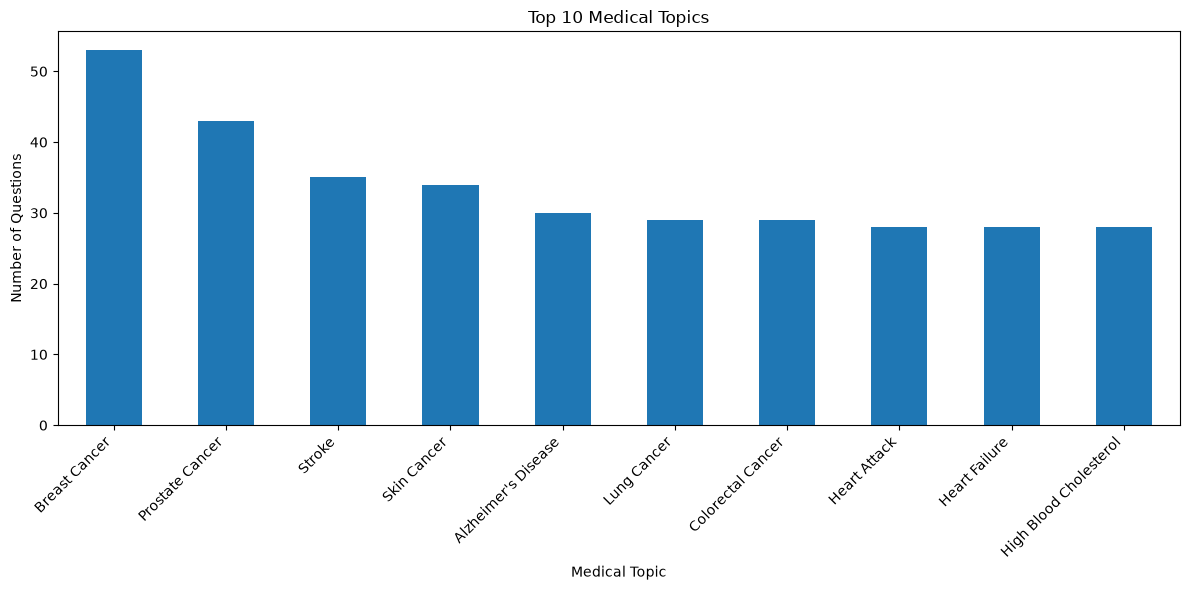

In [14]:
plt.figure(figsize=(12, 6))

medical_df["topic"].value_counts().head(10).plot(
    kind="bar"
)

plt.title("Top 10 Medical Topics")
plt.xlabel("Medical Topic")
plt.ylabel("Number of Questions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

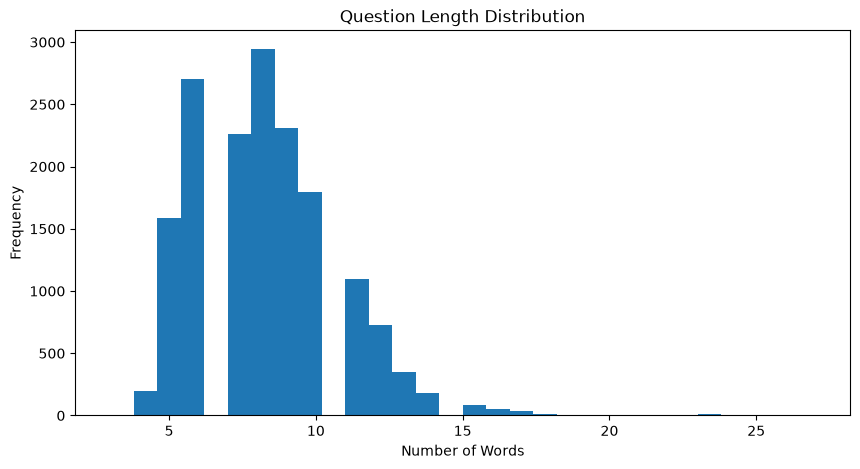

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(
    medical_df["question_length"],
    bins=30
)

plt.title("Question Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [16]:
CSV_PATH = OUTPUT_DIR / "medquad_processed.csv"

medical_df.to_csv(CSV_PATH, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", CSV_PATH)

Cleaned dataset saved successfully!
File location: C:\Users\dilee\outputs\medquad_processed.csv


# Step 5: Text Chunking

Text chunking divides large medical documents into smaller
sections so that the chatbot can retrieve relevant information.

We will use LangChain's RecursiveCharacterTextSplitter.

In [17]:
from langchain_core.documents import Document

documents = []

for index, row in medical_df.iterrows():

    content = (
        "Medical Topic: " + str(row["topic"]) +
        "\nQuestion: " + str(row["question"]) +
        "\nAnswer: " + str(row["answer"])
    )

    document = Document(
        page_content=content,
        metadata={
            "topic": str(row["topic"]),
            "question": str(row["question"]),
            "source": str(row["source_file"])
        }
    )

    documents.append(document)

print("Total medical documents:", len(documents))
print("\nFirst document:")
print(documents[0].page_content)

Total medical documents: 16359

First document:
Medical Topic: Adult Acute Lymphoblastic Leukemia
Question: What is (are) Adult Acute Lymphoblastic Leukemia ?
Answer: Key Points - Adult acute lymphoblastic leukemia (ALL) is a type of cancer in which the bone marrow makes too many lymphocytes (a type of white blood cell). - Leukemia may affect red blood cells, white blood cells, and platelets. - Previous chemotherapy and exposure to radiation may increase the risk of developing ALL. - Signs and symptoms of adult ALL include fever, feeling tired, and easy bruising or bleeding. - Tests that examine the blood and bone marrow are used to detect (find) and diagnose adult ALL. - Certain factors affect prognosis (chance of recovery) and treatment options. Adult acute lymphoblastic leukemia (ALL) is a type of cancer in which the bone marrow makes too many lymphocytes (a type of white blood cell). Adult acute lymphoblastic leukemia (ALL; also called acute lymphocytic leukemia) is a cancer of the

In [18]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=100,
    separators=["\n\n", "\n", ". ", " ", ""]
)

chunks = text_splitter.split_documents(documents)

print("Original documents:", len(documents))
print("Total chunks:", len(chunks))

Original documents: 16359
Total chunks: 46410


In [19]:
for i in range(min(3, len(chunks))):

    print("\n========== CHUNK", i + 1, "==========\n")

    print(chunks[i].page_content[:1000])

    print("\nMetadata:")
    print(chunks[i].metadata)


========== CHUNK 1 ==========

Medical Topic: Adult Acute Lymphoblastic Leukemia
Question: What is (are) Adult Acute Lymphoblastic Leukemia ?

Metadata:
{'topic': 'Adult Acute Lymphoblastic Leukemia', 'question': 'What is (are) Adult Acute Lymphoblastic Leukemia ?', 'source': '0000001_1.xml'}

========== CHUNK 2 ==========

Answer: Key Points - Adult acute lymphoblastic leukemia (ALL) is a type of cancer in which the bone marrow makes too many lymphocytes (a type of white blood cell). - Leukemia may affect red blood cells, white blood cells, and platelets. - Previous chemotherapy and exposure to radiation may increase the risk of developing ALL. - Signs and symptoms of adult ALL include fever, feeling tired, and easy bruising or bleeding. - Tests that examine the blood and bone marrow are used to detect (find) and diagnose adult ALL. - Certain factors affect prognosis (chance of recovery) and treatment options. Adult acute lymphoblastic leukemia (ALL) is a type of cancer in which the 

# Step 6: Generate Text Embeddings

Embeddings convert medical text into numerical vectors.

We will use the Hugging Face model:
sentence-transformers/all-MiniLM-L6-v2

In [20]:
from langchain_huggingface import HuggingFaceEmbeddings

embedding_model = "sentence-transformers/all-MiniLM-L6-v2"

embeddings = HuggingFaceEmbeddings(
    model_name=embedding_model,
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True}
)

print("Embedding model loaded successfully!")

C:\Users\dilee\anaconda3\envs\medical_chatbot\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dilee\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\dilee\anaconda3\envs\medical_chatbot\Lib\site-packages\huggingface_hub\file

Embedding model loaded successfully!


In [21]:
test_text = "What are the symptoms of diabetes?"

test_embedding = embeddings.embed_query(test_text)

print("Embedding generated successfully!")
print("Vector dimensions:", len(test_embedding))
print("First 10 values:", test_embedding[:10])

Embedding generated successfully!
Vector dimensions: 384
First 10 values: [0.026477478444576263, 0.014529558829963207, -0.04400854557752609, 0.09720118343830109, 0.004718061536550522, -0.02188260853290558, 0.1142956018447876, -0.016554173082113266, -0.01332017406821251, -0.0016431744443252683]


# Step 7: Create Vector Database

ChromaDB stores medical document embeddings.

It allows the chatbot to search for medical information
that is relevant to the user's question.

In [23]:
from langchain_chroma import Chroma
from tqdm.auto import tqdm

COLLECTION_NAME = "medical_qa"
BATCH_SIZE = 100

# Remove old collection if it exists
try:
    old_db = Chroma(
        collection_name=COLLECTION_NAME,
        embedding_function=embeddings,
        persist_directory=str(VECTOR_DIR)
    )
    old_db.delete_collection()
    print("Old collection removed.")

except Exception:
    print("Creating new collection.")

# Process documents in batches
vectorstore = None

for start in tqdm(range(0, len(chunks), BATCH_SIZE),
                  desc="Creating medical database"):

    batch = chunks[start:start + BATCH_SIZE]

    if vectorstore is None:
        vectorstore = Chroma.from_documents(
            documents=batch,
            embedding=embeddings,
            collection_name=COLLECTION_NAME,
            persist_directory=str(VECTOR_DIR)
        )
    else:
        vectorstore.add_documents(batch)

print("ChromaDB created successfully!")
print("Total stored chunks:", vectorstore._collection.count())

Old collection removed.


Creating medical database: 100%|██████████| 465/465 [1:21:40<00:00, 10.54s/it]  

ChromaDB created successfully!
Total stored chunks: 46410


In [24]:
print("Database records:", vectorstore._collection.count())
print("Database is ready!")

Database records: 46410
Database is ready!


# Step 8: Test Medical Information Retrieval

We will search the vector database using a sample
medical question and retrieve the most relevant chunks.

In [25]:
query = "What are the symptoms of diabetes?"

retrieved_docs = vectorstore.similarity_search(
    query,
    k=3
)

print("User Question:", query)

for i, doc in enumerate(retrieved_docs, start=1):

    print("\n========== RESULT", i, "==========")

    print(doc.page_content)

    print("\nSource:", doc.metadata.get("source"))

User Question: What are the symptoms of diabetes?

========== RESULT 1 ==========
Medical Topic: Diabetes
Question: What are the symptoms of Diabetes ?

Source: 0000015.xml

========== RESULT 2 ==========
Medical Topic: Diabetes
Question: What are the symptoms of Diabetes ?
Answer: Many people with diabetes experience one or more symptoms, including extreme thirst or hunger, a frequent need to urinate and/or fatigue. Some lose weight without trying. Additional signs include sores that heal slowly, dry, itchy skin, loss of feeling or tingling in the feet and blurry eyesight. Some people with diabetes, however, have no symptoms at all.

Source: 0000015.xml

========== RESULT 3 ==========
Answer: Diabetes is often called a "silent" disease because it can cause serious complications even before you have symptoms. Symptoms can also be so mild that you dont notice them. An estimated 8 million people in the United States have type 2 diabetes and dont know it, according to 2012 estimates by th

In [26]:
query = "What causes heart disease?"

retrieved_docs = vectorstore.similarity_search(
    query,
    k=3
)

print("Question:", query)

for i, doc in enumerate(retrieved_docs, start=1):

    print("\nResult:", i)
    print(doc.page_content[:800])

Question: What causes heart disease?

Result: 1
Medical Topic: Heart Failure
Question: What causes Heart Failure ?

Result: 2
Medical Topic: Heart Failure
Question: What causes Heart Failure ?

Result: 3
Medical Topic: Heart Diseases
Question: What is (are) Heart Diseases ?


# Step 9: Groq LLM Integration

Groq provides the language model that generates answers
using the medical information retrieved from ChromaDB.

We will use the OpenAI GPT-OSS 20B model hosted by Groq.

In [108]:
from getpass import getpass

groq_api_key = getpass("Enter your NEW Groq API key: ").strip()

if not groq_api_key.startswith("gsk_"):
    raise ValueError("Invalid Groq API key.")

print("New API key received successfully!")

Enter your NEW Groq API key:  ········


New API key received successfully!


In [54]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0.2,
    max_tokens=1024,
    api_key=groq_api_key
)

print("Groq initialized successfully!")

Groq initialized successfully!


In [55]:
response = llm.invoke("Explain diabetes in simple English.")

print(response.content)

**Diabetes – a quick, easy‑to‑understand guide**

---

### 1. What is diabetes?
Diabetes is a condition that makes it hard for your body to keep blood sugar (glucose) at a healthy level.  
- **Glucose** is the main fuel that cells use for energy.  
- Your body normally uses a hormone called **insulin** to move glucose from the blood into cells.

When insulin doesn’t work right, glucose stays in the blood and can cause problems.

---

### 2. Types of diabetes

| Type | How it happens | Who it usually affects | Key point |
|------|----------------|------------------------|-----------|
| **Type 1** | The body’s immune system attacks the insulin‑producing cells in the pancreas. | Often starts in children or teens, but can happen at any age. | You need insulin injections or a pump. |
| **Type 2** | The body either doesn’t make enough insulin or the cells don’t use it well (insulin resistance). | Most common in adults, especially if overweight or inactive. | Lifestyle changes (diet, exercise

## Step 40: Create Medical Q&A Prompt

We create a prompt that instructs the AI to answer medical questions
using information retrieved from our MedQuAD knowledge base.

In [56]:
from langchain_core.prompts import ChatPromptTemplate

medical_prompt = ChatPromptTemplate.from_template("""
You are a Medical Information Assistant.

Answer the user's question using ONLY the medical context
provided below.

Rules:
1. Do not invent medical facts.
2. Do not diagnose any disease.
3. Do not prescribe medicines or treatments.
4. If the context does not contain enough information,
   clearly say that the knowledge base does not contain
   sufficient information.
5. Use simple English.
6. Encourage users to consult qualified healthcare
   professionals for personal medical advice.
7. For emergency symptoms, advise seeking emergency care.

Medical Context:
{context}

User Question:
{question}

Answer:
""")

print("Medical prompt created successfully!")

Medical prompt created successfully!


## Step 42: Build the Medical RAG Chatbot

The chatbot will:
1. Accept a medical question.
2. Search the ChromaDB medical knowledge base.
3. Retrieve the four most relevant documents.
4. Send the retrieved information to Groq.
5. Generate an answer based on the medical context.

In [57]:
def medical_chatbot(question):

    # Retrieve relevant medical documents
    retrieved_docs = vectorstore.similarity_search(
        question,
        k=4
    )

    if not retrieved_docs:
        return {
            "answer": "No relevant information found in the medical knowledge base.",
            "sources": []
        }

    # Combine retrieved documents
    context = "\n\n".join(
        doc.page_content for doc in retrieved_docs
    )

    # Create prompt
    formatted_prompt = medical_prompt.format(
        context=context,
        question=question
    )

    # Generate response using Groq
    response = llm.invoke(formatted_prompt)

    return {
        "answer": response.content,
        "sources": retrieved_docs
    }

print("Medical RAG chatbot created successfully!")

Medical RAG chatbot created successfully!


In [58]:
result = medical_chatbot(
    "What is diabetes and what are its symptoms?"
)

print("QUESTION:")
print("What is diabetes and what are its symptoms?")

print("\nCHATBOT ANSWER:")
print(result["answer"])

print("\nSOURCES:")
for doc in result["sources"]:
    print(doc.metadata)

QUESTION:
What is diabetes and what are its symptoms?

CHATBOT ANSWER:
Diabetes is a condition where your blood sugar (glucose) is too high.  
With type 1 diabetes, the pancreas does not make enough insulin, a hormone that helps sugar enter your cells.  
With type 2 diabetes, your body does not use insulin properly or does not make enough of it.

**Common symptoms of diabetes**

- Feeling very thirsty  
- Urinating often or frequently  
- Feeling very hungry or tired  
- Losing weight without trying  
- Having sores that heal slowly  
- Having dry, itchy skin  
- Loss of feeling or tingling in the feet  
- Blurry eyesight  

Some people with diabetes may not notice any symptoms at all.

If you think you might have diabetes or are experiencing any of these signs, please see a qualified healthcare professional for proper testing and advice. If you have severe symptoms such as sudden vision loss, chest pain, or trouble breathing, seek emergency care right away.

SOURCES:
{'question': 'Wha

In [59]:
result = medical_chatbot(
    "What is heart disease?"
)

print("CHATBOT ANSWER:")
print(result["answer"])

print("\nSOURCES:")
for doc in result["sources"]:
    print(doc.metadata)

CHATBOT ANSWER:
I’m sorry, but the information I have does not include a definition of heart disease.  
If you have concerns about heart health, please talk to a qualified healthcare professional for personalized advice.

SOURCES:
{'question': 'What is (are) Heart Diseases ?', 'source': '0000444.xml', 'topic': 'Heart Diseases'}
{'source': '0000066.xml', 'question': 'What is (are) Heart Valve Disease ?', 'topic': 'Heart Valve Disease'}
{'question': 'What is (are) Heart Valve Diseases ?', 'topic': 'Heart Valve Diseases', 'source': '0000449.xml'}
{'topic': 'Heart Disease in Women', 'question': 'What is (are) Heart Disease in Women ?', 'source': '0000443.xml'}


## Step 46: Interactive Medical Q&A Chatbot

Users can enter medical questions and receive answers
from the medical knowledge base.

In [60]:
while True:

    question = input(
        "\nAsk a medical question (type exit to stop): "
    )

    if question.strip().lower() in ["exit", "quit", "stop"]:
        print("Thank you for using the Medical Q&A Chatbot!")
        break

    if not question.strip():
        print("Please enter a question.")
        continue

    try:
        result = medical_chatbot(question)

        print("\nMEDICAL CHATBOT ANSWER:")
        print(result["answer"])

        print("\nDISCLAIMER:")
        print(
            "This information is for educational purposes only. "
            "It is not a substitute for professional medical advice."
        )

    except Exception as error:
        print("An error occurred:", error)


Ask a medical question (type exit to stop):  What symptoms, health conditions, or medications would you like to ask about today?



MEDICAL CHATBOT ANSWER:
Sure! Which symptoms, health conditions, or medications would you like to discuss today?

DISCLAIMER:
This information is for educational purposes only. It is not a substitute for professional medical advice.



Ask a medical question (type exit to stop):  What medical topic or health question can I help you with next?



MEDICAL CHATBOT ANSWER:
You can ask about any of the following topics next:

- How to prevent health problems  
- Understanding medical research  
- Creating a family health history  

Feel free to choose one, and I’ll give you the information that’s in the medical context. If you need personalized advice, please consult a qualified healthcare professional.

DISCLAIMER:
This information is for educational purposes only. It is not a substitute for professional medical advice.



Ask a medical question (type exit to stop):  exit


Thank you for using the Medical Q&A Chatbot!


In [62]:
test_question = "What are the symptoms of diabetes?"

retrieved_docs = vectorstore.similarity_search(
    test_question,
    k=4
)

print("QUESTION:")
print(test_question)

print("\nRETRIEVED MEDICAL DOCUMENTS:")

for i, doc in enumerate(retrieved_docs, start=1):
    print(f"\nDOCUMENT {i}")
    print(doc.page_content[:1000])
    print("Metadata:", doc.metadata)

QUESTION:
What are the symptoms of diabetes?

RETRIEVED MEDICAL DOCUMENTS:

DOCUMENT 1
Medical Topic: Diabetes
Question: What are the symptoms of Diabetes ?
Metadata: {'source': '0000015.xml', 'topic': 'Diabetes', 'question': 'What are the symptoms of Diabetes ?'}

DOCUMENT 2
Medical Topic: Diabetes
Question: What are the symptoms of Diabetes ?
Answer: Many people with diabetes experience one or more symptoms, including extreme thirst or hunger, a frequent need to urinate and/or fatigue. Some lose weight without trying. Additional signs include sores that heal slowly, dry, itchy skin, loss of feeling or tingling in the feet and blurry eyesight. Some people with diabetes, however, have no symptoms at all.
Metadata: {'source': '0000015.xml', 'question': 'What are the symptoms of Diabetes ?', 'topic': 'Diabetes'}

DOCUMENT 3
Answer: Diabetes is often called a "silent" disease because it can cause serious complications even before you have symptoms. Symptoms can also be so mild that you do

In [63]:
test_questions = [
    "What are the symptoms of diabetes?",
    "What causes heart disease?",
    "What is asthma?",
    "What are the symptoms of cancer?",
    "What is hypertension?"
]

for question in test_questions:

    print("\n" + "=" * 60)
    print("QUESTION:", question)

    docs = vectorstore.similarity_search(question, k=3)

    print("\nRETRIEVED DOCUMENTS:")

    for i, doc in enumerate(docs, start=1):
        print(f"\nDocument {i}:")
        print(doc.page_content[:500])

print("\nAll retrieval tests completed!")


QUESTION: What are the symptoms of diabetes?

RETRIEVED DOCUMENTS:

Document 1:
Medical Topic: Diabetes
Question: What are the symptoms of Diabetes ?

Document 2:
Medical Topic: Diabetes
Question: What are the symptoms of Diabetes ?
Answer: Many people with diabetes experience one or more symptoms, including extreme thirst or hunger, a frequent need to urinate and/or fatigue. Some lose weight without trying. Additional signs include sores that heal slowly, dry, itchy skin, loss of feeling or tingling in the feet and blurry eyesight. Some people with diabetes, however, have no symptoms at all.

Document 3:
Answer: Diabetes is often called a "silent" disease because it can cause serious complications even before you have symptoms. Symptoms can also be so mild that you dont notice them. An estimated 8 million people in the United States have type 2 diabetes and dont know it, according to 2012 estimates by the Centers for Disease Control and Prevention (CDC). Common Signs Some common symp

In [64]:
test_questions = [
    "What are the symptoms of diabetes?",
    "What is asthma?",
    "What is hypertension?"
]

for question in test_questions:

    print("\n" + "=" * 60)
    print("QUESTION:", question)

    result = medical_chatbot(question)

    print("\nCHATBOT ANSWER:")
    print(result["answer"])

    print("\nNUMBER OF SOURCES:", len(result["sources"]))


QUESTION: What are the symptoms of diabetes?

CHATBOT ANSWER:
The medical context says that people with diabetes may notice several common symptoms, such as:

- Feeling very thirsty
- Urinating often
- Feeling very hungry or tired
- Losing weight without trying
- Having sores that heal slowly
- Having dry, itchy skin
- Feeling pins‑and‑needles or loss of feeling in the feet
- Seeing blurry vision

Some people with diabetes have no symptoms at all.  

If you think you might have any of these signs, it’s best to talk to a qualified healthcare professional for proper testing and advice. If you experience emergency symptoms (e.g., severe pain, difficulty breathing, or sudden confusion), seek emergency care right away.

NUMBER OF SOURCES: 4

QUESTION: What is asthma?

CHATBOT ANSWER:
I’m sorry, but the information provided does not include a definition of asthma. For a clear explanation, please consult a qualified healthcare professional.

NUMBER OF SOURCES: 4

QUESTION: What is hypertensi

## Step 51: Retrieval Performance Evaluation

Evaluate the relevance of retrieved medical documents
using predefined test questions and expected keywords.

In [65]:
evaluation_data = [
    {
        "question": "What are the symptoms of diabetes?",
        "keywords": ["diabetes", "symptoms"]
    },
    {
        "question": "What causes heart disease?",
        "keywords": ["heart", "disease"]
    },
    {
        "question": "What is asthma?",
        "keywords": ["asthma"]
    },
    {
        "question": "What is hypertension?",
        "keywords": ["hypertension", "blood pressure"]
    },
    {
        "question": "What are the symptoms of cancer?",
        "keywords": ["cancer", "symptoms"]
    }
]

total_relevant = 0
total_retrieved = 0

for item in evaluation_data:

    docs = vectorstore.similarity_search(
        item["question"],
        k=4
    )

    relevant_count = 0

    for doc in docs:

        content = doc.page_content.lower()

        if any(keyword in content for keyword in item["keywords"]):
            relevant_count += 1

    total_relevant += relevant_count
    total_retrieved += len(docs)

    print("\nQuestion:", item["question"])
    print("Retrieved documents:", len(docs))
    print("Relevant documents:", relevant_count)

if total_retrieved > 0:

    retrieval_precision = (
        total_relevant / total_retrieved
    ) * 100

    print("\n" + "=" * 45)
    print("RETRIEVAL EVALUATION RESULTS")
    print("=" * 45)

    print("Total retrieved:", total_retrieved)
    print("Relevant retrieved:", total_relevant)

    print(
        "Keyword-based retrieval precision:",
        round(retrieval_precision, 2),
        "%"
    )


Question: What are the symptoms of diabetes?
Retrieved documents: 4
Relevant documents: 4

Question: What causes heart disease?
Retrieved documents: 4
Relevant documents: 4

Question: What is asthma?
Retrieved documents: 4
Relevant documents: 4

Question: What is hypertension?
Retrieved documents: 4
Relevant documents: 4

Question: What are the symptoms of cancer?
Retrieved documents: 4
Relevant documents: 4

RETRIEVAL EVALUATION RESULTS
Total retrieved: 20
Relevant retrieved: 20
Keyword-based retrieval precision: 100.0 %


## Step 53: Response Time Evaluation

Measure how much time the chatbot takes to generate answers
for medical questions.

In [66]:
# STEP 54: Response Time Evaluation

import time

test_question = "What are the symptoms of diabetes?"

start_time = time.time()

result = medical_chatbot(test_question)

end_time = time.time()

response_time = end_time - start_time

print("Question:", test_question)
print("\nAnswer:")
print(result["answer"])

print("\nResponse Time:", round(response_time, 2), "seconds")

Question: What are the symptoms of diabetes?

Answer:
**Symptoms of diabetes**

People with diabetes may notice one or more of the following:

- Very thirsty (extreme thirst)  
- Frequent need to urinate  
- Feeling very hungry or very tired  
- Unintended weight loss  
- Sores or cuts that heal slowly  
- Dry, itchy skin  
- Tingling, numbness, or loss of feeling in the feet or legs  
- Blurry or changed vision  

Some people have no symptoms at all, so a blood test is needed to confirm diabetes.

If you notice any of these signs, or if you are concerned about your health, please see a qualified healthcare professional for advice. If you experience emergency symptoms such as severe pain, difficulty breathing, or sudden vision loss, seek emergency care right away.

Response Time: 0.95 seconds


## Step 55: Medical Answer Quality Evaluation

Evaluate chatbot answers for completeness, readability,
medical safety and relevance.

In [67]:
# STEP 56: Medical Answer Quality Evaluation

import pandas as pd

quality_tests = [
    {
        "question": "What are the symptoms of diabetes?",
        "expected_keywords": [
            "thirst", "urinate", "tired", "weight"
        ]
    },
    {
        "question": "What is asthma?",
        "expected_keywords": [
            "airway", "breathing"
        ]
    },
    {
        "question": "What is hypertension?",
        "expected_keywords": [
            "blood pressure"
        ]
    }
]

quality_results = []

for test in quality_tests:

    result = medical_chatbot(test["question"])

    answer = result["answer"].lower()

    matched = [
        word for word in test["expected_keywords"]
        if word in answer
    ]

    score = (
        len(matched) / len(test["expected_keywords"])
    ) * 100

    quality_results.append({
        "Question": test["question"],
        "Matched Keywords": len(matched),
        "Expected Keywords": len(test["expected_keywords"]),
        "Keyword Coverage (%)": round(score, 2),
        "Answer Length": len(result["answer"])
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)

print(
    "Average Keyword Coverage:",
    round(quality_df["Keyword Coverage (%)"].mean(), 2),
    "%"
)

,Question,Matched Keywords,Expected Keywords,Keyword Coverage (%),Answer Length
0,What are the symptoms of diabetes?,3,4,75.0,675
1,What is asthma?,0,2,0.0,236
2,What is hypertension?,1,1,100.0,869


Average Keyword Coverage: 58.33 %


In [68]:
# STEP 57: Test unrelated questions

question = "Who won the FIFA World Cup in 2022?"

result = medical_chatbot(question)

print("QUESTION:", question)
print("\nCHATBOT ANSWER:")
print(result["answer"])

QUESTION: Who won the FIFA World Cup in 2022?

CHATBOT ANSWER:
I’m sorry, but the provided medical context does not contain information about the FIFA World Cup. I don’t have that answer.


## Step 58: Display Retrieved Medical Sources

Display the source documents retrieved from the MedQuAD
knowledge base along with the chatbot's answer.

In [69]:
# STEP 59: Medical Answer with Sources

def ask_medical_question(question):

    result = medical_chatbot(question)

    print("\nQUESTION:")
    print(question)

    print("\nMEDICAL CHATBOT ANSWER:")
    print(result["answer"])

    print("\nRETRIEVED SOURCES:")

    if result["sources"]:
        for i, doc in enumerate(result["sources"], start=1):
            print(f"\nSource {i}:")
            print("Topic:", doc.metadata.get("focus_area", "Not available"))
            print("Content:", doc.page_content[:400])
    else:
        print("No sources found.")

    print("\nDISCLAIMER:")
    print("For educational purposes only. Consult a qualified healthcare professional for personal medical advice.")

In [70]:
# STEP 60: Test source display

ask_medical_question(
    "What are the symptoms of diabetes?"
)


QUESTION:
What are the symptoms of diabetes?

MEDICAL CHATBOT ANSWER:
The medical context says that people with diabetes may notice several symptoms, such as:

- Very thirsty
- Urinating often
- Feeling very hungry
- Feeling very tired
- Losing weight without trying
- Having sores that heal slowly
- Dry, itchy skin
- Tingling or loss of feeling in the feet
- Blurry eyesight

Some people have no symptoms at all.  

If you think you might have diabetes, it’s best to see a qualified healthcare professional for testing and advice. If you have emergency symptoms (e.g., severe pain, trouble breathing, or unconsciousness), seek emergency care right away.

RETRIEVED SOURCES:

Source 1:
Topic: Not available
Content: Medical Topic: Diabetes
Question: What are the symptoms of Diabetes ?

Source 2:
Topic: Not available
Content: Medical Topic: Diabetes
Question: What are the symptoms of Diabetes ?
Answer: Many people with diabetes experience one or more symptoms, including extreme thirst or hunger

In [71]:
# STEP 61: Save evaluation results

quality_df.to_csv(
    OUTPUT_DIR / "medical_chatbot_evaluation.csv",
    index=False
)

print("Evaluation results saved successfully!")
print("File: outputs/medical_chatbot_evaluation.csv")

Evaluation results saved successfully!
File: outputs/medical_chatbot_evaluation.csv


In [72]:
# STEP 62: Save project summary

project_summary = {
    "Project Name": "Medical Q&A Chatbot",
    "Dataset": "MedQuAD",
    "Embedding Model": "sentence-transformers/all-MiniLM-L6-v2",
    "Vector Database": "ChromaDB",
    "LLM": "Groq - openai/gpt-oss-20b",
    "Framework": "LangChain",
    "Architecture": "Retrieval-Augmented Generation (RAG)",
    "Interface": "Jupyter Notebook"
}

summary_df = pd.DataFrame(
    list(project_summary.items()),
    columns=["Component", "Details"]
)

display(summary_df)

summary_df.to_csv(
    OUTPUT_DIR / "project_summary.csv",
    index=False
)

print("Project summary saved successfully!")

,Component,Details
0,Project Name,Medical Q&A Chatbot
1,Dataset,MedQuAD
2,Embedding Model,sentence-transformers/all-MiniLM-L6-v2
3,Vector Database,ChromaDB
4,LLM,Groq - openai/gpt-oss-20b
5,Framework,LangChain
6,Architecture,Retrieval-Augmented Generation (RAG)
7,Interface,Jupyter Notebook


Project summary saved successfully!


In [73]:
# STEP 63: Install Streamlit

%pip install streamlit python-dotenv

  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.2 MB 3.6 MB/s eta 0:00:03
   ---- ----------------------------------- 1.3/11.2 MB 2.6 MB/s eta 0:00:04
   -------- ------------------------------- 2.4/11.2 MB 3.0 MB/s eta 0:00:03
   ----------- ---------------------------- 3.1/11.2 MB 3.3 MB/s eta 0:00:03
   ---------------- ----------------------- 4.7/11.2 MB 4.1 MB/s eta 0:00:02
   ---------------------- ----------------- 6.3/11.2 MB 4.6 MB/s eta 0:00:02
   --------------------------- ------------ 7.9/11.2 MB 5.0 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.2 MB 5.2 MB/s eta 0:00:01
   ---------------------------------------  11.0/11.2 MB 5.5 MB/s eta 0:00:01
   ---------------------------------------- 11.2/11.2 MB 5.4 MB/s  0:00:02
   -------------------

In [74]:
# STEP 64: Check project directory

from pathlib import Path

PROJECT_DIR = Path.cwd()

print("Project directory:", PROJECT_DIR)
print("\nProject files:")

for item in PROJECT_DIR.iterdir():
    print(item.name)

Project directory: C:\Users\dilee

Project files:
.anaconda
.android
.bash_history
.cache
.codex
.conda
.continuum
.copilot
.gitconfig
.github-copilot-cli
.ipynb_checkpoints
.ipython
.jupyter
.keras
.lesshst
.matplotlib
.streamlit
.virtual_documents
.vscode
.vscode-shared
AI_RAG_Chatbot.ipynb
anaconda3
anaconda_projects
AppData
Application Data
best_pneumonia_mobilenetv2.pth
BikeRentalProject
Contacts
Cookies
cosmetics_env
cosmetics_recommender
data
Downloads
ecommerce-app
Favorites
git-journey
git-one
Intelligent_RAG_Chatbot.ipynb
Jobby-app
Links
Local Settings
Medical Image Classification.ipynb
Medical_QA_Chatbot.ipynb
Microsoft
MLA
Music
My Documents
NetHood
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{61b188f1-e287-11f0-b018-89a1a1d40132}.TM.blf
NTUSER.DAT{61b188f1-e287-11f0-b018-89a1a1d40132}.TMContainer00000000000000000001.regtrans-ms
NTUSER.DAT{61b188f1-e287-11f0-b018-89a1a1d40132}.TMContainer00000000000000000002.regtrans-ms
ntuser.ini
OneDrive
outputs
pandas
Pictures
P

In [75]:
# STEP 65: Create Streamlit application file

app_file = PROJECT_DIR / "app.py"

app_file.touch(exist_ok=True)

print("Streamlit application file created!")
print("Location:", app_file)

Streamlit application file created!
Location: C:\Users\dilee\app.py


In [76]:
# STEP 66: Save Groq API key securely

from getpass import getpass

new_key = getpass("Enter your NEW Groq API key: ").strip()

if not new_key.startswith("gsk_"):
    raise ValueError("Please enter the correct Groq API key.")

env_file = PROJECT_DIR / ".env"

env_file.write_text(
    f'GROQ_API_KEY="{new_key}"\n',
    encoding="utf-8"
)

print("Groq API key saved securely in .env")

Enter your NEW Groq API key:  ········


Groq API key saved securely in .env


In [77]:
# STEP 67: Create Streamlit Medical Chatbot

app_code = r'''
import streamlit as st
import os
from pathlib import Path
from dotenv import load_dotenv

from langchain_groq import ChatGroq
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.prompts import ChatPromptTemplate

# Project configuration
BASE_DIR = Path(__file__).parent
load_dotenv(BASE_DIR / ".env")

st.set_page_config(
    page_title="Medical Q&A Chatbot",
    page_icon="🩺",
    layout="centered"
)

# Application heading
st.title("🩺 Medical Q&A Chatbot")
st.write("Ask questions about medical conditions and health topics.")

st.info(
    "Educational information only. This chatbot cannot diagnose "
    "diseases or prescribe medicines."
)

# Load database and language model
@st.cache_resource
def load_chatbot():

    api_key = os.getenv("GROQ_API_KEY")

    if not api_key:
        raise ValueError("Groq API key not found in .env file.")

    vector_dir = BASE_DIR / "vectorstore" / "chroma_db"

    embeddings = HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2"
    )

    vectorstore = Chroma(
        collection_name="medical_qa",
        embedding_function=embeddings,
        persist_directory=str(vector_dir)
    )

    llm = ChatGroq(
        model="openai/gpt-oss-20b",
        temperature=0.2,
        max_tokens=1024,
        api_key=api_key
    )

    return vectorstore, llm


medical_prompt = ChatPromptTemplate.from_template("""
You are a Medical Information Assistant.

Answer using ONLY the medical context below.

Rules:
1. Do not invent medical facts.
2. Do not diagnose diseases.
3. Do not prescribe medicines or treatments.
4. If the context is insufficient, say so clearly.
5. Use simple English.
6. Recommend consulting a qualified healthcare professional.
7. For emergency symptoms, advise seeking emergency care.

Medical Context:
{context}

Question:
{question}

Answer:
""")


def get_medical_answer(question, vectorstore, llm):

    docs = vectorstore.similarity_search(question, k=4)

    if not docs:
        return (
            "The medical knowledge base does not contain "
            "sufficient information for this question."
        ), []

    context = "\n\n".join(doc.page_content for doc in docs)

    prompt = medical_prompt.format(
        context=context,
        question=question
    )

    response = llm.invoke(prompt)

    return response.content, docs


# Initialize chatbot
try:
    vectorstore, llm = load_chatbot()
    st.success("Medical knowledge base connected successfully!")

except Exception as error:
    st.error(f"Unable to initialize chatbot: {error}")
    st.stop()


# Chat history
if "messages" not in st.session_state:
    st.session_state.messages = []


for message in st.session_state.messages:

    with st.chat_message(message["role"]):
        st.markdown(message["content"])

        if message.get("sources"):
            with st.expander("View medical sources"):
                for i, source in enumerate(message["sources"], 1):
                    st.markdown(f"**Source {i}**")
                    st.write(source.page_content[:500])


# User question
question = st.chat_input("Ask your medical question...")

if question:

    st.session_state.messages.append({
        "role": "user",
        "content": question
    })

    with st.chat_message("user"):
        st.markdown(question)

    with st.chat_message("assistant"):

        with st.spinner("Searching medical knowledge base..."):

            try:
                answer, sources = get_medical_answer(
                    question,
                    vectorstore,
                    llm
                )

                st.markdown(answer)

                with st.expander("View medical sources"):
                    for i, source in enumerate(sources, 1):
                        st.markdown(f"**Source {i}**")
                        st.write(source.page_content[:500])

                st.session_state.messages.append({
                    "role": "assistant",
                    "content": answer,
                    "sources": [
                        {"content": doc.page_content}
                        for doc in sources
                    ]
                })

            except Exception as error:
                st.error(f"An error occurred: {error}")


st.caption(
    "Medical Q&A Chatbot | Built using Python, LangChain, "
    "Hugging Face, ChromaDB and Groq"
)
'''

app_file = PROJECT_DIR / "app.py"

app_file.write_text(app_code, encoding="utf-8")

print("app.py created successfully!")
print("File location:", app_file)

app.py created successfully!
File location: C:\Users\dilee\app.py


In [78]:
# STEP 68: Verify app.py

app_file = PROJECT_DIR / "app.py"

print("File exists:", app_file.exists())
print("File size:", app_file.stat().st_size, "bytes")

File exists: True
File size: 4624 bytes


In [80]:
# STEP 69: Launch Streamlit

!streamlit run app.py

^C


In [82]:
from pathlib import Path

app_file = Path("app.py")

if app_file.exists():
    print("app.py found successfully!")
    print("File size:", app_file.stat().st_size, "bytes")
else:
    print("ERROR: app.py not found!")

app.py found successfully!
File size: 4624 bytes


In [83]:
!streamlit run app.py

^C


In [84]:
from pathlib import Path

requirements = """
pandas
numpy
matplotlib
tqdm
requests
streamlit
python-dotenv
langchain
langchain-core
langchain-community
langchain-text-splitters
langchain-huggingface
langchain-chroma
langchain-groq
sentence-transformers
chromadb
"""

requirements_file = Path("requirements.txt")
requirements_file.write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully!")
print(requirements_file.resolve())

requirements.txt created successfully!
C:\Users\dilee\requirements.txt


In [85]:
print(requirements_file.read_text(encoding="utf-8"))

pandas
numpy
matplotlib
tqdm
requests
streamlit
python-dotenv
langchain
langchain-core
langchain-community
langchain-text-splitters
langchain-huggingface
langchain-chroma
langchain-groq
sentence-transformers
chromadb



In [86]:
from pathlib import Path

gitignore_content = """
# API keys and secrets
.env
.env.*

# Python cache
__pycache__/
*.pyc

# Virtual environments
.venv/
venv/

# Jupyter checkpoints
.ipynb_checkpoints/

# Generated database
vectorstore/chroma_db/

# Temporary files
*.log
.DS_Store
"""

gitignore_file = Path(".gitignore")

gitignore_file.write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print(".gitignore created successfully!")
print(gitignore_file.resolve())

.gitignore created successfully!
C:\Users\dilee\.gitignore


In [87]:
print(gitignore_file.read_text(encoding="utf-8"))

# API keys and secrets
.env
.env.*

# Python cache
__pycache__/
*.pyc

# Virtual environments
.venv/
venv/

# Jupyter checkpoints
.ipynb_checkpoints/

# Generated database
vectorstore/chroma_db/

# Temporary files
*.log
.DS_Store



In [88]:
from pathlib import Path

readme_content = """
# Medical Q&A Chatbot

## 1. Project Overview

The Medical Q&A Chatbot is an AI-powered application
that answers medical-related questions using a
medical question-answer dataset.

It uses Retrieval-Augmented Generation (RAG) to
retrieve relevant medical information and generate
answers in simple English.

## 2. Project Objectives

- Build an AI-based medical question-answering system.
- Retrieve relevant information from medical documents.
- Generate context-based answers using an LLM.
- Provide a simple web interface using Streamlit.

## 3. Technologies Used

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib
- LangChain
- Hugging Face Embeddings
- ChromaDB
- Groq LLM
- Streamlit

## 4. Dataset

MedQuAD (Medical Question Answering Dataset).

## 5. Project Architecture

1. Download medical dataset.
2. Extract and clean medical questions and answers.
3. Split text into smaller chunks.
4. Generate embeddings.
5. Store embeddings in ChromaDB.
6. Retrieve relevant medical documents.
7. Generate answers using Groq LLM.
8. Display answers through Streamlit.

## 6. Project Structure

- data/ : Medical dataset
- vectorstore/ : ChromaDB database
- outputs/ : Evaluation results
- app.py : Streamlit application
- requirements.txt : Required Python libraries
- .env : Groq API key (private)
- .gitignore : Files excluded from GitHub

## 7. Installation

Install the required libraries:

    pip install -r requirements.txt

Configure your Groq API key in the .env file:

    GROQ_API_KEY=your_groq_api_key

Do not share or upload your .env file.

## 8. Run the Application

Start the Streamlit application:

    streamlit run app.py

Open:

    http://localhost:8501

## 9. Features

- Medical question answering
- Semantic document retrieval
- Context-based answer generation
- Medical source display
- Interactive Streamlit interface

## 10. Medical Disclaimer

This chatbot is for educational and informational
purposes only. It does not provide medical diagnosis,
prescriptions, or professional medical advice.

Always consult a qualified healthcare professional
for personal medical concerns.
"""

readme_file = Path("README.md")
readme_file.write_text(readme_content.strip() + "\n", encoding="utf-8")

print("README.md created successfully!")
print(readme_file.resolve())

README.md created successfully!
C:\Users\dilee\README.md


In [89]:
print(readme_file.read_text(encoding="utf-8"))

# Medical Q&A Chatbot

## 1. Project Overview

The Medical Q&A Chatbot is an AI-powered application
that answers medical-related questions using a
medical question-answer dataset.

It uses Retrieval-Augmented Generation (RAG) to
retrieve relevant medical information and generate
answers in simple English.

## 2. Project Objectives

- Build an AI-based medical question-answering system.
- Retrieve relevant information from medical documents.
- Generate context-based answers using an LLM.
- Provide a simple web interface using Streamlit.

## 3. Technologies Used

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib
- LangChain
- Hugging Face Embeddings
- ChromaDB
- Groq LLM
- Streamlit

## 4. Dataset

MedQuAD (Medical Question Answering Dataset).

## 5. Project Architecture

1. Download medical dataset.
2. Extract and clean medical questions and answers.
3. Split text into smaller chunks.
4. Generate embeddings.
5. Store embeddings in ChromaDB.
6. Retrieve relevant medical documen

In [90]:
import os

print("Notebook location:", os.getcwd())
print("\nFiles in this location:")
print(os.listdir())

Notebook location: C:\Users\dilee

Files in this location:
['.agents', '.anaconda', '.android', '.bash_history', '.cache', '.codex', '.conda', '.continuum', '.copilot', '.env', '.gitconfig', '.github-copilot-cli', '.gitignore', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.lesshst', '.matplotlib', '.streamlit', '.virtual_documents', '.vscode', '.vscode-shared', 'AI_RAG_Chatbot.ipynb', 'anaconda3', 'anaconda_projects', 'app.py', 'AppData', 'Application Data', 'best_pneumonia_mobilenetv2.pth', 'BikeRentalProject', 'Contacts', 'Cookies', 'cosmetics_env', 'cosmetics_recommender', 'data', 'Downloads', 'ecommerce-app', 'Favorites', 'git-journey', 'git-one', 'Intelligent_RAG_Chatbot.ipynb', 'Jobby-app', 'Links', 'Local Settings', 'Medical Image Classification.ipynb', 'Medical-QA-Chatbot.ipynb', 'Medical_QA_Chatbot.ipynb', 'Microsoft', 'MLA', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{61b188f1-e287-11f0-b018-89a1a1d40132}.TM.

In [91]:
from pathlib import Path

base = Path.cwd()

for name in ["app.py", "requirements.txt", "README.md", ".gitignore"]:
    file = base / name
    print(name, "FOUND" if file.exists() else "NOT FOUND")

print("\nApp.py first 15 lines:")
with open(base / "app.py", "r", encoding="utf-8") as f:
    for i in range(15):
        line = f.readline()
        if not line:
            break
        print(line, end="")

app.py FOUND
requirements.txt FOUND
README.md FOUND
.gitignore FOUND

App.py first 15 lines:

import streamlit as st
import os
from pathlib import Path
from dotenv import load_dotenv

from langchain_groq import ChatGroq
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.prompts import ChatPromptTemplate

# Project configuration
BASE_DIR = Path(__file__).parent
load_dotenv(BASE_DIR / ".env")



In [92]:
from pathlib import Path

base = Path.cwd()

print("REQUIREMENTS.TXT:")
print((base / "requirements.txt").read_text(encoding="utf-8"))

print("\nREADME.MD — first 30 lines:")
print("\n".join((base / "README.md").read_text(encoding="utf-8").splitlines()[:30]))

print("\nOUTPUTS FOLDER:")
print([str(p.relative_to(base)) for p in (base / "outputs").rglob("*") if p.is_file()] if (base / "outputs").exists() else "Not found")

print("\nVECTORSTORE FOLDER:")
print([str(p.relative_to(base)) for p in (base / "vectorstore").rglob("*") if p.is_file()][:20] if (base / "vectorstore").exists() else "Not found")

REQUIREMENTS.TXT:
pandas
numpy
matplotlib
tqdm
requests
streamlit
python-dotenv
langchain
langchain-core
langchain-community
langchain-text-splitters
langchain-huggingface
langchain-chroma
langchain-groq
sentence-transformers
chromadb


README.MD — first 30 lines:
# Medical Q&A Chatbot

## 1. Project Overview

The Medical Q&A Chatbot is an AI-powered application
that answers medical-related questions using a
medical question-answer dataset.

It uses Retrieval-Augmented Generation (RAG) to
retrieve relevant medical information and generate
answers in simple English.

## 2. Project Objectives

- Build an AI-based medical question-answering system.
- Retrieve relevant information from medical documents.
- Generate context-based answers using an LLM.
- Provide a simple web interface using Streamlit.

## 3. Technologies Used

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib
- LangChain
- Hugging Face Embeddings
- ChromaDB
- Groq LLM
- Streamlit

OUTPUTS FOLDER:
['outputs\\medical

In [93]:
from pathlib import Path

base = Path.cwd()

files = [
    "Medical-QA-Chatbot.ipynb",
    "Medical_QA_Chatbot.ipynb",
    "app.py",
    "requirements.txt",
    "README.md",
    ".gitignore",
    "outputs/medquad_processed.csv",
    "outputs/medical_chatbot_evaluation.csv",
    "outputs/project_summary.csv",
]

for name in files:
    p = base / name
    if p.exists():
        print(f"{name} | {p.stat().st_size / 1024:.1f} KB | {p.stat().st_mtime}")
    else:
        print(f"{name} | NOT FOUND")

print("\nChromaDB total size:")
db = base / "vectorstore" / "chroma_db"
if db.exists():
    total = sum(p.stat().st_size for p in db.rglob("*") if p.is_file())
    print(f"{total / (1024 * 1024):.2f} MB")

Medical-QA-Chatbot.ipynb | 206.5 KB | 1794474994.473857
Medical_QA_Chatbot.ipynb | 8.2 KB | 1794460492.3619895
app.py | 4.5 KB | 1794471683.8044958
requirements.txt | 0.2 KB | 1794472356.3908978
README.md | 2.2 KB | 1794472453.1157675
.gitignore | 0.2 KB | 1794472396.4583645
outputs/medquad_processed.csv | 21760.3 KB | 1794461885.080459
outputs/medical_chatbot_evaluation.csv | 0.2 KB | 1794471451.995564
outputs/project_summary.csv | 0.3 KB | 1794471459.2191217

ChromaDB total size:
287.76 MB


In [94]:
from pathlib import Path

base = Path.cwd()

for name in ["Medical-QA-Chatbot.ipynb", "app.py", "README.md"]:
    p = base / name
    if p.exists():
        content = p.read_text(encoding="utf-8")
        found = "gsk_" in content or "gsk-" in content
        print(f"{name}: {'POSSIBLE API KEY FOUND — DO NOT UPLOAD' if found else 'No obvious Groq key found'}")

print("\n.gitignore contents:")
print((base / ".gitignore").read_text(encoding="utf-8"))

Medical-QA-Chatbot.ipynb: POSSIBLE API KEY FOUND — DO NOT UPLOAD
app.py: No obvious Groq key found
README.md: No obvious Groq key found

.gitignore contents:
# API keys and secrets
.env
.env.*

# Python cache
__pycache__/
*.pyc

# Virtual environments
.venv/
venv/

# Jupyter checkpoints
.ipynb_checkpoints/

# Generated database
vectorstore/chroma_db/

# Temporary files
*.log
.DS_Store



In [95]:
import json
from pathlib import Path

file = Path.cwd() / "Medical-QA-Chatbot.ipynb"

notebook = json.loads(file.read_text(encoding="utf-8"))

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if "gsk_" in source or "gsk-" in source:
        print(f"Possible API key found in cell {i + 1}")

Possible API key found in cell 36
Possible API key found in cell 65


In [96]:
from pathlib import Path
import shutil

source = Path.cwd()
destination = Path.home() / "OneDrive" / "Downloads" / "Medical-QA-Chatbot"

destination.mkdir(parents=True, exist_ok=True)

files = [
    "Medical-QA-Chatbot.ipynb",
    "app.py",
    "requirements.txt",
    "README.md",
    ".gitignore",
]

for name in files:
    shutil.copy2(source / name, destination / name)

print("Project files copied successfully!")
print("Location:", destination)
print("Files:", [p.name for p in destination.iterdir() if p.is_file()])

Project files copied successfully!
Location: C:\Users\dilee\OneDrive\Downloads\Medical-QA-Chatbot
Files: ['.gitignore', 'app.py', 'Medical-QA-Chatbot.ipynb', 'README.md', 'requirements.txt']


In [97]:
from pathlib import Path
import shutil

source = Path.cwd() / "outputs"
destination = Path.home() / "OneDrive" / "Downloads" / "Medical-QA-Chatbot" / "outputs"

destination.mkdir(parents=True, exist_ok=True)

for name in [
    "medical_chatbot_evaluation.csv",
    "project_summary.csv",
    "medquad_processed.csv"
]:
    shutil.copy2(source / name, destination / name)

print("CSV files copied successfully!")
print([p.name for p in destination.iterdir()])


CSV files copied successfully!
['medical_chatbot_evaluation.csv', 'medquad_processed.csv', 'project_summary.csv']


In [98]:
import json
import re
from pathlib import Path

file = Path.cwd() / "Medical-QA-Chatbot.ipynb"
notebook = json.loads(file.read_text(encoding="utf-8"))

pattern = re.compile(r"gsk_[A-Za-z0-9_-]{20,}")

found = False

for i, cell in enumerate(notebook["cells"], 1):
    source = "".join(cell.get("source", []))
    outputs = json.dumps(cell.get("outputs", []))

    if pattern.search(source) or pattern.search(outputs):
        print(f"Possible actual API key found in cell {i}")
        found = True

if not found:
    print("No actual Groq API key found in notebook.")

Possible actual API key found in cell 36


In [104]:
import json
import re
from pathlib import Path

file = Path.cwd() / "Medical-QA-Chatbot.ipynb"
notebook = json.loads(file.read_text(encoding="utf-8"))

pattern = re.compile(r"gsk_[A-Za-z0-9_-]{20,}")
found = False

for i, cell in enumerate(notebook["cells"], 1):
    source = "".join(cell.get("source", []))
    outputs = json.dumps(cell.get("outputs", []))

    if pattern.search(source) or pattern.search(outputs):
        print("Possible API key found in cell:", i)
        found = True

if not found:
    print("No actual Groq API key found in notebook.")

Possible API key found in cell: 36


In [105]:
import json
import re
from pathlib import Path

file = Path.cwd() / "Medical-QA-Chatbot.ipynb"
nb = json.loads(file.read_text(encoding="utf-8"))

cell = nb["cells"][35]

source = "".join(cell.get("source", []))
outputs = json.dumps(cell.get("outputs", []))

pattern = re.compile(r"gsk_[A-Za-z0-9_-]{20,}")

print("Actual key in code:", bool(pattern.search(source)))
print("Actual key in output:", bool(pattern.search(outputs)))

Actual key in code: True
Actual key in output: True


In [109]:
import json
import re
from pathlib import Path

file = Path.cwd() / "Medical-QA-Chatbot.ipynb"
nb = json.loads(file.read_text(encoding="utf-8"))

pattern = re.compile(r"gsk_[A-Za-z0-9_-]{20,}")

for i, cell in enumerate(nb["cells"], 1):
    source = "".join(cell.get("source", []))
    outputs = json.dumps(cell.get("outputs", []))

    if pattern.search(source) or pattern.search(outputs):
        print("Possible API key found in cell:", i)

print("Security scan completed.")

Security scan completed.
